In [7]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- Settings ----------
fs = 2000                  # sampling rate in Hz (samples per second)
duration = 1.0             # window length in seconds
N = int(fs * duration)     # number of samples = 2000
t = np.arange(N) / fs      # time axis: 0, 0.0005, 0.001, ... seconds

rng = np.random.default_rng(42)   # random generator; seed 42 gives repeatable results

CLASSES = ["No activity", "Human footsteps", "Light vehicle", "Other vibration"]

# ---------- Helper: add a decaying burst (one "thump") ----------
def add_burst(x, start_time, freq, tau, amp):
    """Adds a decaying sine wave to x starting at start_time (seconds)."""
    start = int(start_time * fs)
    if start >= len(x):
        return
    L = int(0.3 * fs)                       # burst lasts up to 0.3 s
    L = min(L, len(x) - start)              # don't run past the end
    tb = np.arange(L) / fs
    x[start:start + L] += amp * np.exp(-tb / tau) * np.sin(2 * np.pi * freq * tb)

# ---------- Class 0: No activity ----------
def make_no_activity():
    return rng.normal(0, 0.02, N)           # only small random noise

# ---------- Class 1: Human footsteps ----------
def make_footsteps():
    x = rng.normal(0, 0.02, N)
    period = rng.uniform(0.5, 0.7)          # time between steps (about 1.5-2 steps/s)
    first = rng.uniform(0, period)
    for ts in np.arange(first, duration, period):
        add_burst(x, ts,
                  freq=rng.uniform(20, 40), # low-frequency thump
                  tau=0.05,                 # fades out quickly
                  amp=rng.uniform(0.3, 0.6))
    return x

# ---------- Class 2: Light vehicle ----------
def make_vehicle():
    f0 = rng.uniform(25, 50)                # engine/rolling hum frequency
    phase = rng.uniform(0, 2 * np.pi, 3)
    x = sum((1 / k) * np.sin(2 * np.pi * k * f0 * t + phase[k - 1]) for k in (1, 2, 3))
    envelope = 1 + 0.2 * np.sin(2 * np.pi * 0.5 * t + rng.uniform(0, 2 * np.pi))
    return 0.5 * x * envelope + rng.normal(0, 0.03, N)

# ---------- Class 3: Other vibration ----------
def make_other():
    x = rng.normal(0, 0.03, N)
    for _ in range(rng.integers(1, 4)):     # 1 to 3 sharp knocks
        add_burst(x, rng.uniform(0, 0.8),
                  freq=rng.uniform(80, 150),  # higher-frequency, sharper
                  tau=0.02,
                  amp=rng.uniform(0.6, 1.0))
    return x

GENERATORS = [make_no_activity, make_footsteps, make_vehicle, make_other]

def make_window(label):
    """Returns one 1-second window for the class number (0 to 3)."""
    return GENERATORS[label]()

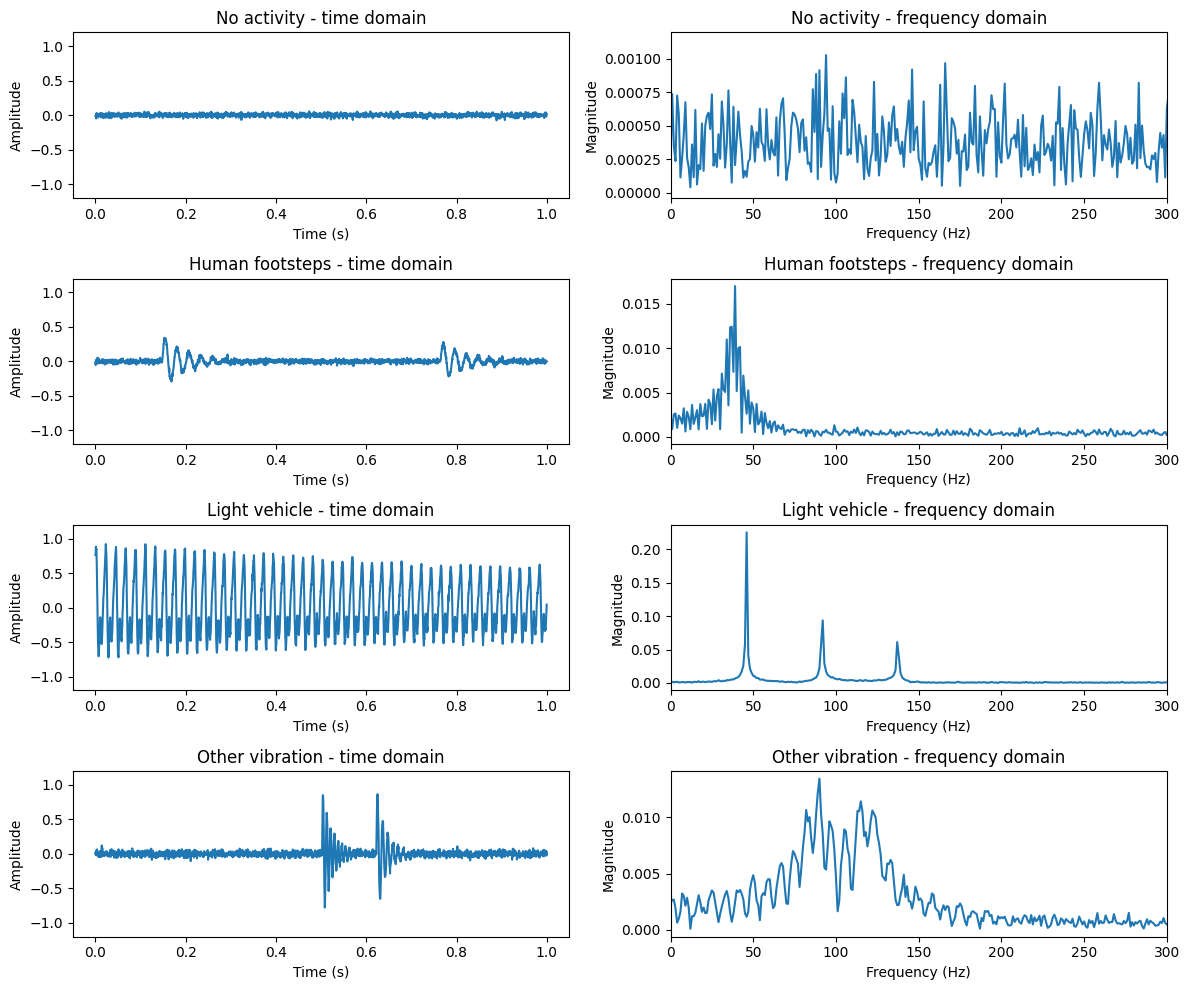

In [13]:
fig, axes = plt.subplots(4, 2, figsize=(12, 10))

for label in range(4):
    x = make_window(label)

    # Left column: waveform in time
    axes[label, 0].plot(t, x)
    axes[label, 0].set_title(CLASSES[label] + " - time domain")
    axes[label, 0].set_ylim(-1.2, 1.2)
    axes[label, 0].set_xlabel("Time (s)")
    axes[label, 0].set_ylabel("Amplitude")

    # Right column: frequency content (FFT)
    spectrum = np.abs(np.fft.rfft(x)) / N
    freqs = np.fft.rfftfreq(N, 1 / fs)
    axes[label, 1].plot(freqs, spectrum)
    axes[label, 1].set_xlim(0, 300)
    axes[label, 1].set_title(CLASSES[label] + " - frequency domain")
    axes[label, 1].set_xlabel("Frequency (Hz)")
    axes[label, 1].set_ylabel("Magnitude")

plt.tight_layout()
plt.show()